In [2]:


import pandas as pd
import networkx as nx
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.cm as cm
import matplotlib.colors as mcolors

path = r"raw_data_colombian_politics.xlsx"
df = pd.read_excel(path, sheet_name=1)
print("Dimensions:", df.shape)
columnas_excluir = ["NOMBRE", "EDAD", "GENERO",
    "PARTIDO_POLITICO", "NIVEL_DE_ESTUDIOS", "UNIVERSIDAD",
    "CARRERA", "PREDECESORES", "GOBERNACION",
    "FLAG_MINISTERIO", "FLAG_VIVO"]
columnas_cargos = []
for col in df.columns:
    if col in columnas_excluir:
        continue
    valores = set(df[col].dropna().unique())
    if valores.issubset({0, 1}):
        columnas_cargos.append(col)
B = nx.Graph()
for _, row in df.iterrows():
    nombre = row["NOMBRE"]
    B.add_node(nombre, bipartite="persona", tipo="persona",
        edad=row.get("EDAD"),
        genero=row.get("GENERO"),
        partido=row.get("PARTIDO_POLITICO"),
        nivel_estudios=row.get("NIVEL_DE_ESTUDIOS"),
        universidad=row.get("UNIVERSIDAD"),
        carrera=row.get("CARRERA"),
        predecesores=row.get("PREDECESORES"),
        gobernacion=row.get("GOBERNACION"),
        flag_ministerio=row.get("FLAG_MINISTERIO"),
        flag_vivo=row.get("FLAG_VIVO"))
for cargo in columnas_cargos:
    B.add_node(cargo, bipartite="cargo", tipo="cargo")
for _, row in df.iterrows():
    nombre = row["NOMBRE"]
    for cargo in columnas_cargos:
        if row[cargo] == 1:
            B.add_edge(nombre, cargo, relacion="occupies")
print("Bipartite graph")
print("Nodes:", B.number_of_nodes())
print("Edges:", B.number_of_edges())
personas = {n for n, d in B.nodes(data=True) if d["tipo"] == "persona"}
cargos = {n for n, d in B.nodes(data=True) if d["tipo"] == "cargo"}
print("Number of persons:", len(personas))
print("Number of positions:", len(cargos))
from networkx.algorithms import bipartite
G_personas = bipartite.weighted_projected_graph(B, personas)
print("Projected graph of persons")
print("Nodes:", G_personas.number_of_nodes())
print("Edges:", G_personas.number_of_edges())


Dimensions: (265, 62)
Bipartite graph
Nodes: 314
Edges: 379
Number of persons: 264
Number of positions: 50
Projected graph of persons
Nodes: 264
Edges: 2014


C:\Users\carlo\AppData\Local\Temp\ipykernel_22536\2823704794.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.03, 0.88, 0.96])


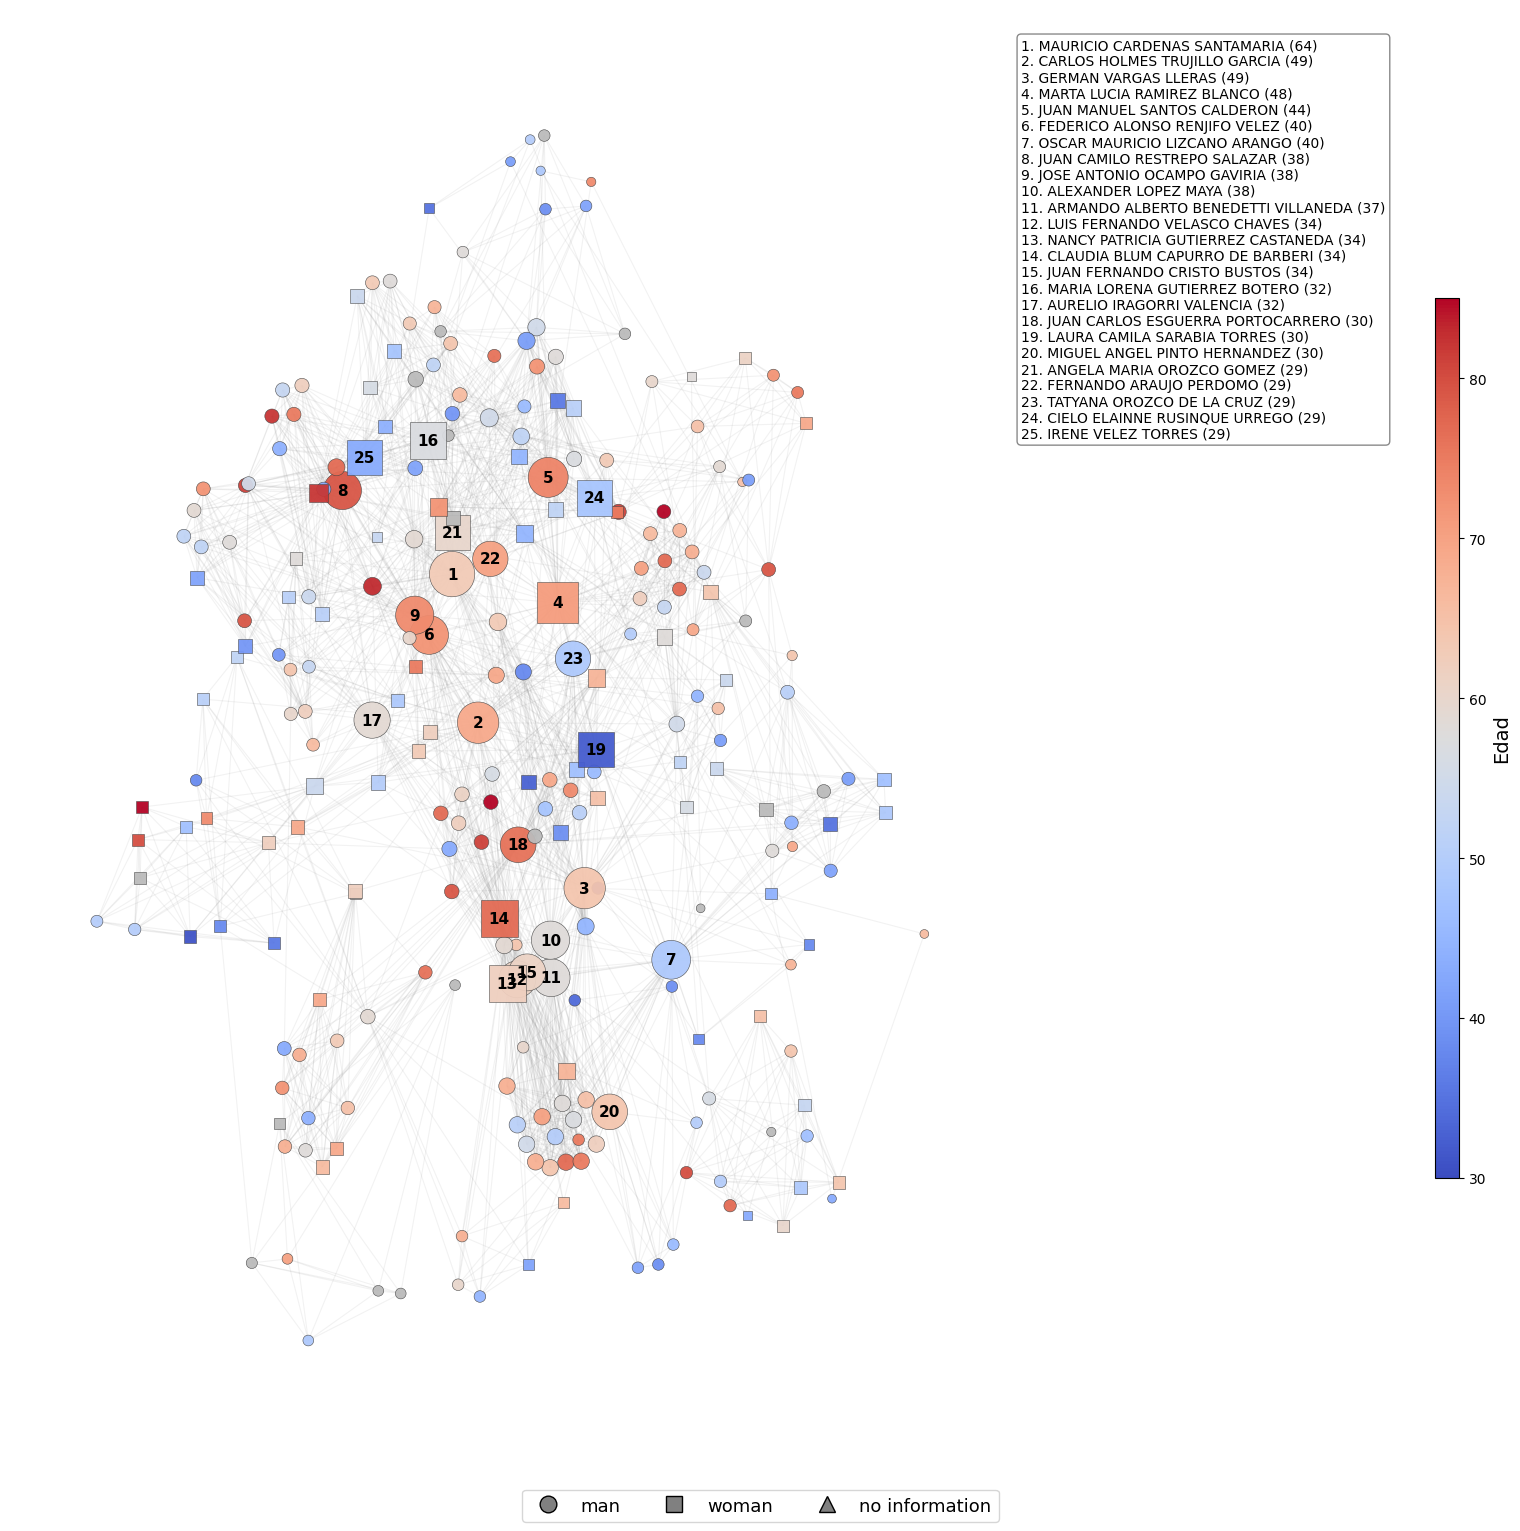

In [10]:

genero_dict = dict(zip(df["NOMBRE"], df["GENERO"]))
edad_dict = dict(zip(df["NOMBRE"], df["EDAD"]))
gob_dict = dict(zip(df["NOMBRE"], df["GOBERNACION"]))
grados = dict(G_personas.degree())
top_n = 25
top_nodes = sorted(grados.items(), key=lambda x: x[1], reverse=True)[:top_n]
top_names = [x[0] for x in top_nodes]
edades_validas = [edad_dict[n] for n in G_personas.nodes() if pd.notna(edad_dict.get(n))]
norm = mcolors.Normalize(vmin=min(edades_validas), vmax=max(edades_validas))
cmap = cm.coolwarm
pos = nx.spring_layout(G_personas, k=3.05, iterations=400, seed=42)
fig, ax = plt.subplots(figsize=(16,16))
nx.draw_networkx_edges(G_personas, pos, ax=ax, alpha=0.10, width=0.8, edge_color="gray")
hombres = []
mujeres = []
otros = []
for n in G_personas.nodes():
    genero = str(genero_dict.get(n, "")).upper()
    if genero.startswith("M"):
        hombres.append(n)
    elif genero.startswith("F"):
        mujeres.append(n)
    else:
        otros.append(n)
color_map = {}
for n in G_personas.nodes():
    edad = edad_dict.get(n)
    if pd.isna(edad):
        color_map[n] = "#BBBBBB"
    else:
        color_map[n] = cmap(norm(edad))
node_sizes = {}
for n in G_personas.nodes():
    g = grados[n]
    if n in top_names:
        node_sizes[n] = 300 + g * 12
    else:
        node_sizes[n] = 30 + g * 5
nx.draw_networkx_nodes(G_personas, pos, nodelist=hombres, node_shape='o',
    node_size=[node_sizes[n] for n in hombres], node_color=[color_map[n] for n in hombres],
    edgecolors="#444444", linewidths=0.4, alpha=0.95, ax=ax)
nx.draw_networkx_nodes(G_personas, pos, nodelist=mujeres, node_shape='s',
    node_size=[node_sizes[n] for n in mujeres], node_color=[color_map[n] for n in mujeres],
    edgecolors="#444444", linewidths=0.4, alpha=0.95, ax=ax)
nx.draw_networkx_nodes(G_personas, pos, nodelist=otros, node_shape='^', 
    node_size=[node_sizes[n] for n in otros ], node_color=[color_map[n] for n in otros],
    edgecolors="#444444", linewidths=0.4, alpha=0.95, ax=ax)
labels = {}
leyenda_top = []
for idx, (node, grado) in enumerate(top_nodes, start=1):
    labels[node] = str(idx)
    leyenda_top.append(f"{idx}. {node} ({grado})")
nx.draw_networkx_labels(G_personas,pos,labels=labels,font_size=11,font_weight="bold",font_color="black",ax=ax)
texto_leyenda = "\n".join(leyenda_top)
ax.text(1.01, 0.98, texto_leyenda, transform=ax.transAxes, fontsize=10,
    verticalalignment="top", bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray", alpha=0.92))
sm = cm.ScalarMappable(cmap=cmap,norm=norm)
sm.set_array([])
cbar_ax = fig.add_axes([0.90, 0.22, 0.015, 0.55])
cbar = fig.colorbar(sm,cax=cbar_ax)
cbar.set_label("Edad",fontsize=14)
legend_elements = [
    Line2D([0], [0],marker='o', color='w', label='man', markerfacecolor='gray', markeredgecolor='black', markersize=12),
    Line2D([0], [0],marker='s',color='w',label='woman',markerfacecolor='gray',markeredgecolor='black',markersize=12),
    Line2D([0], [0],marker='^',color='w',label='no information',markerfacecolor='gray',markeredgecolor='black',markersize=12)
]
fig.legend(handles=legend_elements,loc="lower center",ncol=3,fontsize=13)
ax.axis("off")
plt.tight_layout(rect=[0, 0.03, 0.88, 0.96])
plt.show()